# 02: Error analysis of the U-Net baseline

Stage 4 of [PLAN.md](../PLAN.md). Out-of-fold predictions of `unet_r34` with its tuned post-processing
(threshold 0.5, minimum area 300 px) are taken apart to decide what Stage 5 should fix.

1. Overall score and how each true filament was treated, compared with human-vs-human disagreement
2. Breakdowns by category, size, position on the disk and site
3. Missed filaments and near-misses
4. Anatomy of the predicted components: true matches, annotator disagreement, false positives
5. Outline width: are masks too thin or too wide?
6. Fragmentation: does linking nearby pieces help?
7. Rescoring components with a small classifier
8. Visual gallery

`FOLDS` selects which folds' OOF maps to analyze (only fold 0 exists at the time of writing). Results are cached in
`outputs/<EXP>/analysis/`. Conclusions: [notes/error_analysis.md](../notes/error_analysis.md).

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, cv2
from sklearn.metrics import roc_auc_score
from sklearn.inspection import permutation_importance
from sklearn.ensemble import HistGradientBoostingClassifier

from filament.paths import get_data_paths, get_output_dir
from filament.data import load_coco, annotation_table, annotator_image_table
from filament.folds import load_folds
from filament.evaluation import GroundTruth, load_prob
from filament.inference import load_postprocess
from filament.postprocess import find_components
from filament.preprocess import read_image
from filament.rle import rle_to_mask
from filament import error_analysis as ea

EXP, FOLDS = "unet_r34", [0]
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

paths = get_data_paths()
ann = annotation_table(load_coco(paths.annotations)); ai = annotator_image_table(load_coco(paths.annotations))
folds = load_folds(); stems = folds.stem[folds.fold.isin(FOLDS)].tolist()
PROB_DIR = get_output_dir(EXP) / "oof"
OUT = get_output_dir(f"{EXP}/analysis"); TAG = "fold" + "".join(map(str, FOLDS))
cfg = load_postprocess(get_output_dir(EXP) / "postprocess.json")
gt_cache = GroundTruth(ann, stems)
print(cfg, "|", len(stems), "images,", sum(len(v) for v in gt_cache.by_stem.values()), "annotator-images")

def cached(name, fn):
    path = OUT / f"{name}_{TAG}.csv"
    if path.exists():
        return pd.read_csv(path)
    df = fn(); df.to_csv(path, index=False); return df

if not (OUT / f"gt_{TAG}.csv").exists() or not (OUT / f"pred_{TAG}.csv").exists():
    g, p = ea.build_tables(PROB_DIR, paths.train_images, ann, stems, cfg)
    g.to_csv(OUT / f"gt_{TAG}.csv", index=False); p.to_csv(OUT / f"pred_{TAG}.csv", index=False)
gt = pd.read_csv(OUT / f"gt_{TAG}.csv"); pred = pd.read_csv(OUT / f"pred_{TAG}.csv")
pred["kind"] = ea.pred_category(pred)

PostConfig(threshold=0.5, min_area=300, min_score=0.0, disk_scale=1.0, link_px=0) | 142 images, 235 annotator-images


## 1. Overall score and outcome of each true filament

PQResult(pq=0.3908, sq=0.6764, rq=0.5777, tp=1091, fp=1043, fn=552, n_images=235)
                match  low_iou  missing  split  merged
model           0.664    0.124    0.118  0.058   0.035
human vs human  0.536    0.195    0.178  0.029   0.063


Text(0, 0.5, 'share of GT filaments')

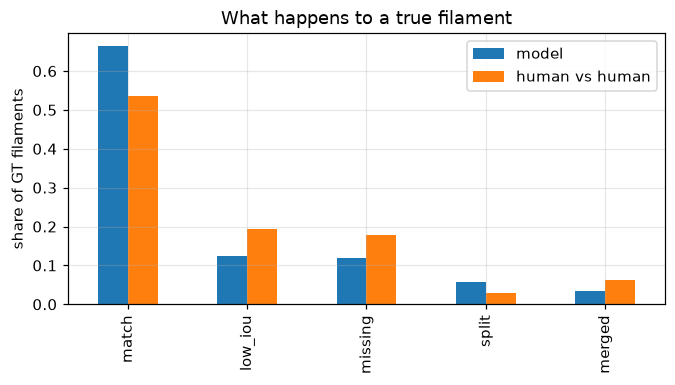

In [2]:
base = ea.pq_variant(PROB_DIR, paths.train_images, gt_cache, cfg)
print(base)
HUMAN = {"match": .536, "low_iou": .195, "missing": .178, "split": .029, "merged": .063}
comp = pd.DataFrame({"model": gt.outcome.value_counts(normalize=True), "human vs human": pd.Series(HUMAN)}).reindex(ea.OUTCOMES)
print(comp.round(3).T)
comp.plot.bar(figsize=(7, 3.2), title="What happens to a true filament"); plt.ylabel("share of GT filaments")

## 2. Breakdowns

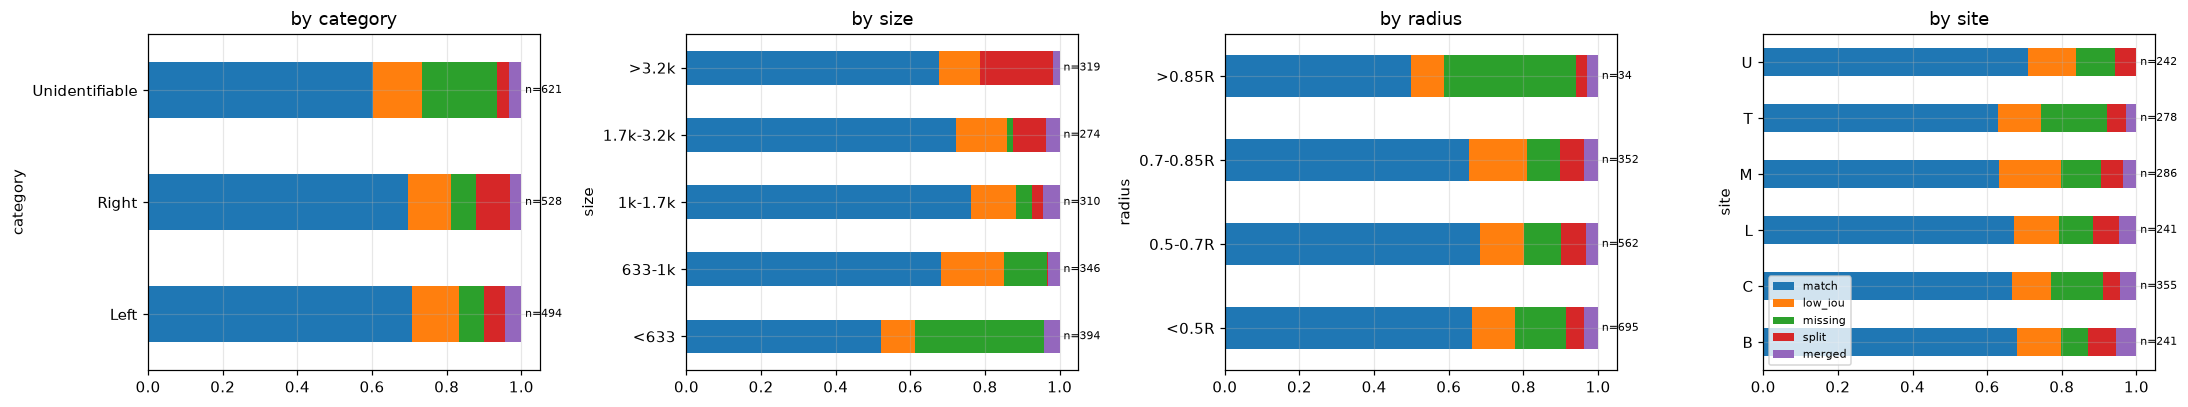

In [3]:
gt["size"] = pd.cut(gt.area, [0, 633, 1053, 1695, 3163, 1e9], labels=["<633", "633-1k", "1k-1.7k", "1.7k-3.2k", ">3.2k"])
gt["radius"] = pd.cut(gt.r_norm, [0, .5, .7, .85, 1.1], labels=["<0.5R", "0.5-0.7R", "0.7-0.85R", ">0.85R"])
fig, axes = plt.subplots(1, 4, figsize=(20, 3.8))
for ax, col in zip(axes, ["category", "size", "radius", "site"]):
    tab = pd.crosstab(gt[col], gt.outcome, normalize="index")[ea.OUTCOMES]
    tab.plot.barh(stacked=True, ax=ax, legend=col == "site", title=f"by {col}")
    for i, n in enumerate(gt[col].value_counts().reindex(tab.index)):
        ax.text(1.01, i, f"n={n}", va="center", fontsize=7)
axes[-1].legend(fontsize=7, loc="lower left"); plt.tight_layout()

## 3. Missed filaments and near-misses

194 missed: 110 were predicted (max prob > 0.5) but their component was removed by the size filter or covered by a non-matching piece; 77 were not seen at all
204 near-misses (overlap but IoU <= 0.5): 59% have IoU in (0.4, 0.5]


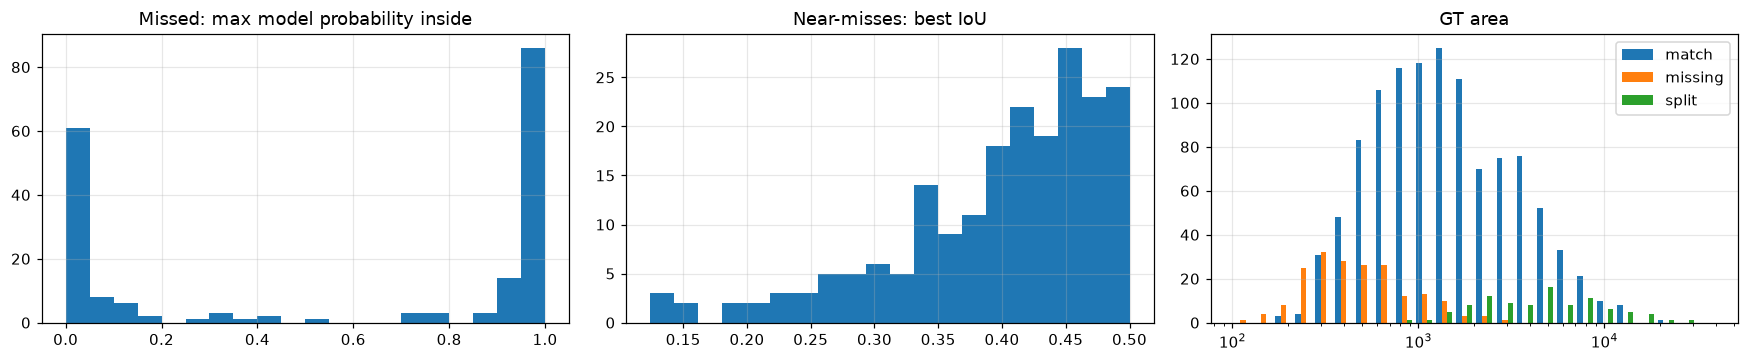

In [4]:
miss = gt[gt.outcome == "missing"]
print(f"{len(miss)} missed: {(miss.prob_max > 0.5).sum()} were predicted (max prob > 0.5) but their component was "
      f"removed by the size filter or covered by a non-matching piece; {(miss.prob_max < 0.2).sum()} were not seen at all")
low = gt[gt.outcome == "low_iou"]
print(f"{len(low)} near-misses (overlap but IoU <= 0.5): {(low.best_iou > 0.4).mean():.0%} have IoU in (0.4, 0.5]")
fig, ax = plt.subplots(1, 3, figsize=(16, 3.4))
ax[0].hist(miss.prob_max, bins=20); ax[0].set_title("Missed: max model probability inside")
ax[1].hist(low.best_iou, bins=20); ax[1].set_title("Near-misses: best IoU")
ax[2].hist([gt[gt.outcome == o].area for o in ["match", "missing", "split"]], bins=np.logspace(2, 4.6, 25),
           label=["match", "missing", "split"]); ax[2].set_xscale("log"); ax[2].legend(); ax[2].set_title("GT area")
plt.tight_layout()

## 4. Anatomy of the predicted components

Every thresholded component (before the size filter):
* `match_all`: a true positive for every annotator of the image
* `match_some`: a true positive for some annotators only (**annotator disagreement**)
* `overlap_no_match`: touches a true filament but IoU ≤ 0.5 for everyone (boundary or fragment problem)
* `pure_fp`: touches no annotator's filament at all

kept:    {'match_all': 582, 'pure_fp': 261, 'overlap_no_match': 261, 'match_some': 183}
multi-annotated images only: {'match_some': 0.327, 'match_all': 0.32, 'overlap_no_match': 0.2, 'pure_fp': 0.154}
dropped by size filter: {'pure_fp': 403, 'overlap_no_match': 186, 'match_all': 19, 'match_some': 16}
                    area  mean_prob  contrast  elongation   length  r_norm
kind                                                                      
match_all         1363.5      0.969     0.127       3.818  106.851   0.558
match_some        1084.0      0.963     0.115       3.730   86.179   0.579
overlap_no_match   987.0      0.957     0.107       3.663   81.171   0.574
pure_fp            636.0      0.946     0.111       3.401   65.108   0.699


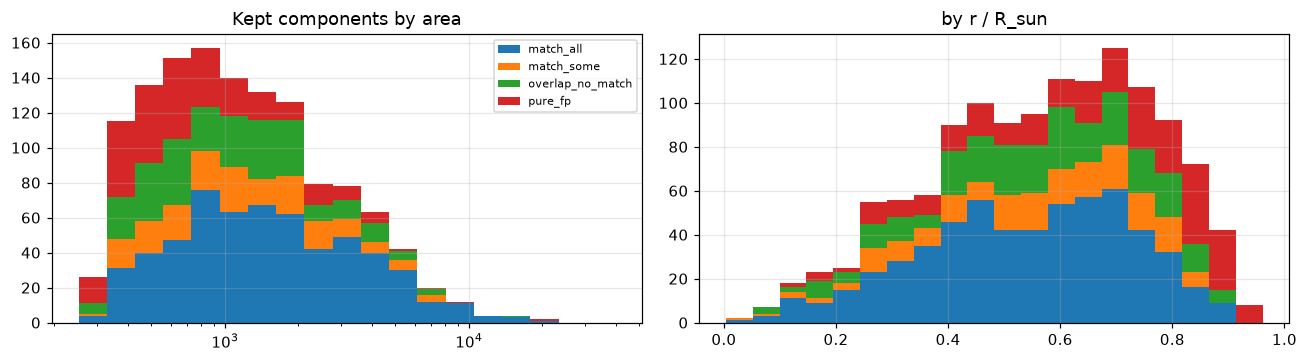

In [5]:
kept, dropped = pred[pred.kept], pred[~pred.kept]
print("kept:   ", kept.kind.value_counts().to_dict())
print("multi-annotated images only:", kept[kept.n_annotators > 1].kind.value_counts(normalize=True).round(3).to_dict())
print("dropped by size filter:", dropped.kind.value_counts().to_dict())
print(kept.groupby("kind")[["area", "mean_prob", "contrast", "elongation", "length", "r_norm"]].median().round(3))
fig, ax = plt.subplots(1, 2, figsize=(12, 3.4))
order = ["match_all", "match_some", "overlap_no_match", "pure_fp"]
ax[0].hist([kept[kept.kind == c].area for c in order], bins=np.logspace(2.4, 4.6, 20), stacked=True, label=order)
ax[0].set_xscale("log"); ax[0].legend(fontsize=7); ax[0].set_title("Kept components by area")
ax[1].hist([kept[kept.kind == c].r_norm for c in order], bins=20, stacked=True, label=order); ax[1].set_title("by r / R_sun")
plt.tight_layout()

## 5. Outline width: grow or shrink every predicted mask

In [6]:
def morph_table():
    rows = []
    for k in [-2, -1, 0, 1, 2]:
        r = ea.pq_variant(PROB_DIR, paths.train_images, gt_cache, cfg, morph_px=k)
        rows.append({"morph_px": k, "pq": r.pq, "sq": r.sq, "rq": r.rq, "tp": r.tp, "fp": r.fp, "fn": r.fn})
    return pd.DataFrame(rows)
print(cached("morph", morph_table).round(4).to_string(index=False))

 morph_px     pq     sq     rq   tp   fp  fn
       -2 0.2529 0.6277 0.4030  761 1373 882
       -1 0.3762 0.6652 0.5655 1068 1066 575
        0 0.3908 0.6764 0.5777 1091 1043 552
        1 0.3629 0.6583 0.5512 1041 1093 602
        2 0.2956 0.6244 0.4734  894 1240 749


## 6. Fragmentation: link pieces closer than about 2 × `link_px`

In [7]:
from filament.evaluation import grid_search
link = cached("link", lambda: grid_search(PROB_DIR, gt_cache, paths.train_images, [cfg.threshold], [200, 300, 400],
                                          [0.0], link_pxs=[0, 2, 4, 6, 10, 15], workers=4))
print(link.pivot_table(index="link_px", columns="min_area", values="pq").round(4))

min_area     200     300     400
link_px                         
0         0.3858  0.3908  0.3928
2         0.3880  0.3928  0.3947
4         0.3901  0.3945  0.3937
6         0.3900  0.3945  0.3941
10        0.3867  0.3906  0.3889
15        0.3835  0.3869  0.3855


## 7. Rescoring components

A gradient-boosted classifier predicts whether a component matches at least one annotator from cheap features
(log area, mean probability, local contrast, elongation, length, r / R, site). Predictions are out-of-fold *within*
the analyzed images (grouped by image). Components with predicted probability < `min_p` are dropped.

In [8]:
pred["p"] = ea.rescoring_oof(pred)
print(f"AUC all components {roc_auc_score(pred.matched_any, pred.p):.3f} | kept only "
      f"{roc_auc_score(kept.matched_any, pred.loc[kept.index, 'p']):.3f} | area alone (kept) "
      f"{roc_auc_score(kept.matched_any, kept.area):.3f}")
pmap = {(s, c): v for s, c, v in zip(pred.stem, pred.comp, pred.p)}

def rescoring_table():
    rows = []
    for size_filter in [True, False]:
        for t in [0, .1, .2, .3, .4, .5]:
            r = ea.pq_variant(PROB_DIR, paths.train_images, gt_cache, cfg, use_size_filter=size_filter,
                              keep_fn=lambda s, ids, t=t: [pmap[(s, int(i))] >= t for i in ids])
            rows.append({"size_filter_300": size_filter, "min_p": t, "pq": r.pq, "tp": r.tp, "fp": r.fp, "fn": r.fn})
    return pd.DataFrame(rows)
res = cached("rescoring", rescoring_table)
print(res.round(4).to_string(index=False))

X, y = ea.component_features(pred), pred.matched_any.astype(int)
clf = HistGradientBoostingClassifier(max_iter=200, learning_rate=0.05, max_leaf_nodes=15, random_state=0).fit(X, y)
imp = permutation_importance(clf, X, y, scoring="roc_auc", n_repeats=5, random_state=0)
print(pd.Series(imp.importances_mean, index=X.columns).sort_values(ascending=False).round(3).rename("AUC drop when shuffled"))

AUC all components 0.883 | kept only 0.778 | area alone (kept) 0.663
 size_filter_300  min_p     pq   tp   fp  fn
            True    0.0 0.3908 1091 1043 552
            True    0.1 0.4073 1071  847 572
            True    0.2 0.4144 1042  721 601
            True    0.3 0.4193 1014  622 629
            True    0.4 0.4144  962  548 681
            True    0.5 0.4097  909  466 734
           False    0.0 0.3192 1131 2014 512
           False    0.1 0.4063 1103  927 540
           False    0.2 0.4146 1068  778 575
           False    0.3 0.4201 1035  663 608
           False    0.4 0.4147  977  581 666
           False    0.5 0.4104  922  493 721


mean_prob     0.229
log_area      0.063
r_norm        0.057
contrast      0.054
length        0.046
elongation    0.025
site_code     0.014
Name: AUC drop when shuffled, dtype: float64


## 8. Gallery

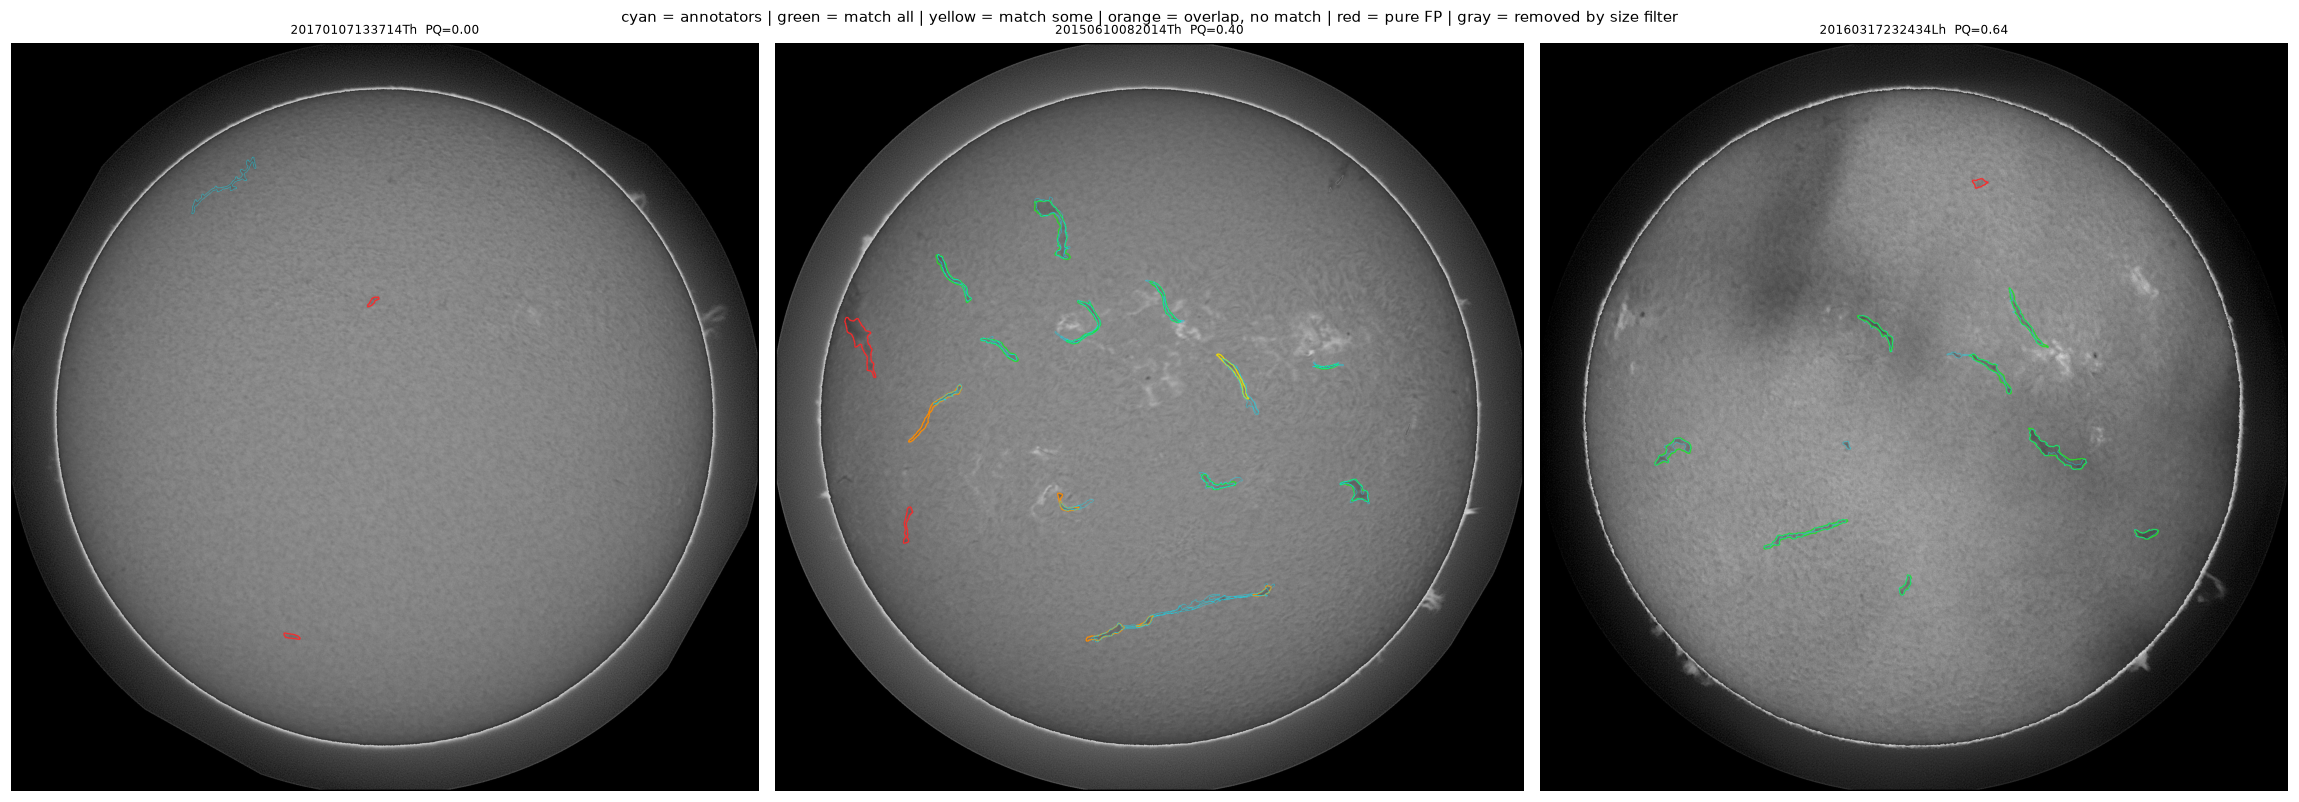

In [9]:
COLORS = {"match_all": (40, 220, 40), "match_some": (240, 220, 0), "overlap_no_match": (255, 140, 0), "pure_fp": (255, 40, 40)}

def overlay(stem, crop=None, ax=None, title=""):
    img = read_image(paths.train_images / f"{stem}.jpeg")
    vis = cv2.cvtColor(img, cv2.COLOR_GRAY2RGB)
    comps = find_components(load_prob(PROB_DIR, stem), cfg.threshold, None, cfg.link_px)
    rows = pred[pred.stem == stem].set_index("comp")
    for i, r in rows.iterrows():
        m = (comps.labels == i).astype(np.uint8)
        cs, _ = cv2.findContours(m, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
        cv2.drawContours(vis, cs, -1, COLORS[r.kind] if r.kept else (150, 150, 150), 2 if r.kept else 1)
    for aid in ai[ai.stem == stem].annotator_image:   # every annotator's outline in cyan
        for rle in ann[ann.annotator_image == aid].rle:
            cs, _ = cv2.findContours(rle_to_mask(rle).astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
            cv2.drawContours(vis, cs, -1, (0, 230, 255), 1)
    if crop:
        y0, y1, x0, x1 = crop; vis = vis[max(y0, 0):y1, max(x0, 0):x1]
    ax.imshow(vis); ax.set_title(title, fontsize=8); ax.axis("off")

per_img = base.per_image().assign(stem=lambda d: d.key.str.split("-", n=1).str[1]).groupby("stem").pq.mean().sort_values()
fig, axes = plt.subplots(1, 3, figsize=(21, 7.4))
for ax, stem in zip(axes, [per_img.index[0], per_img.index[len(per_img) // 2], per_img.index[-1]]):
    overlay(stem, ax=ax, title=f"{stem}  PQ={per_img[stem]:.2f}")
plt.suptitle("cyan = annotators | green = match all | yellow = match some | orange = overlap, no match | "
             "red = pure FP | gray = removed by size filter", fontsize=10); plt.tight_layout()

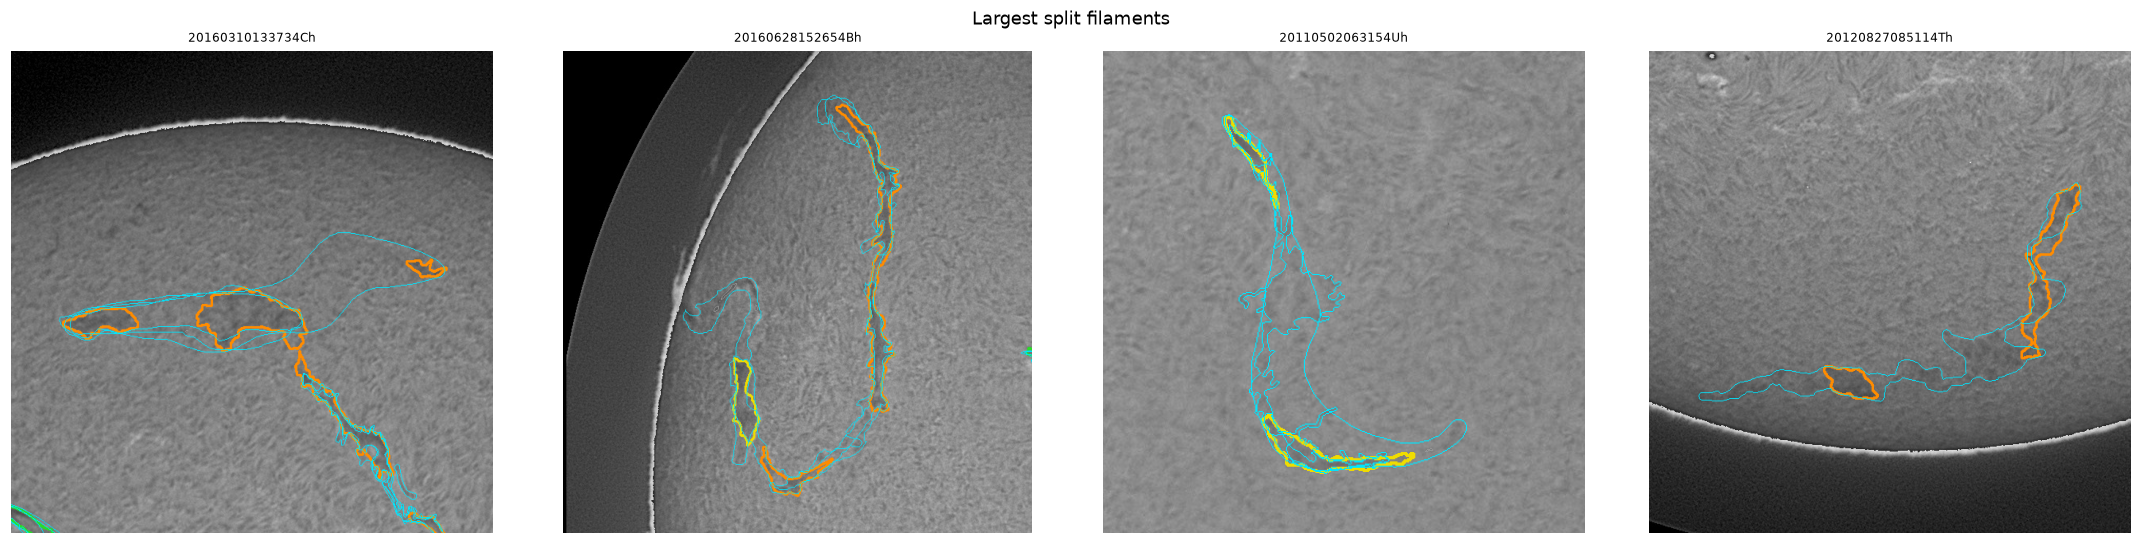

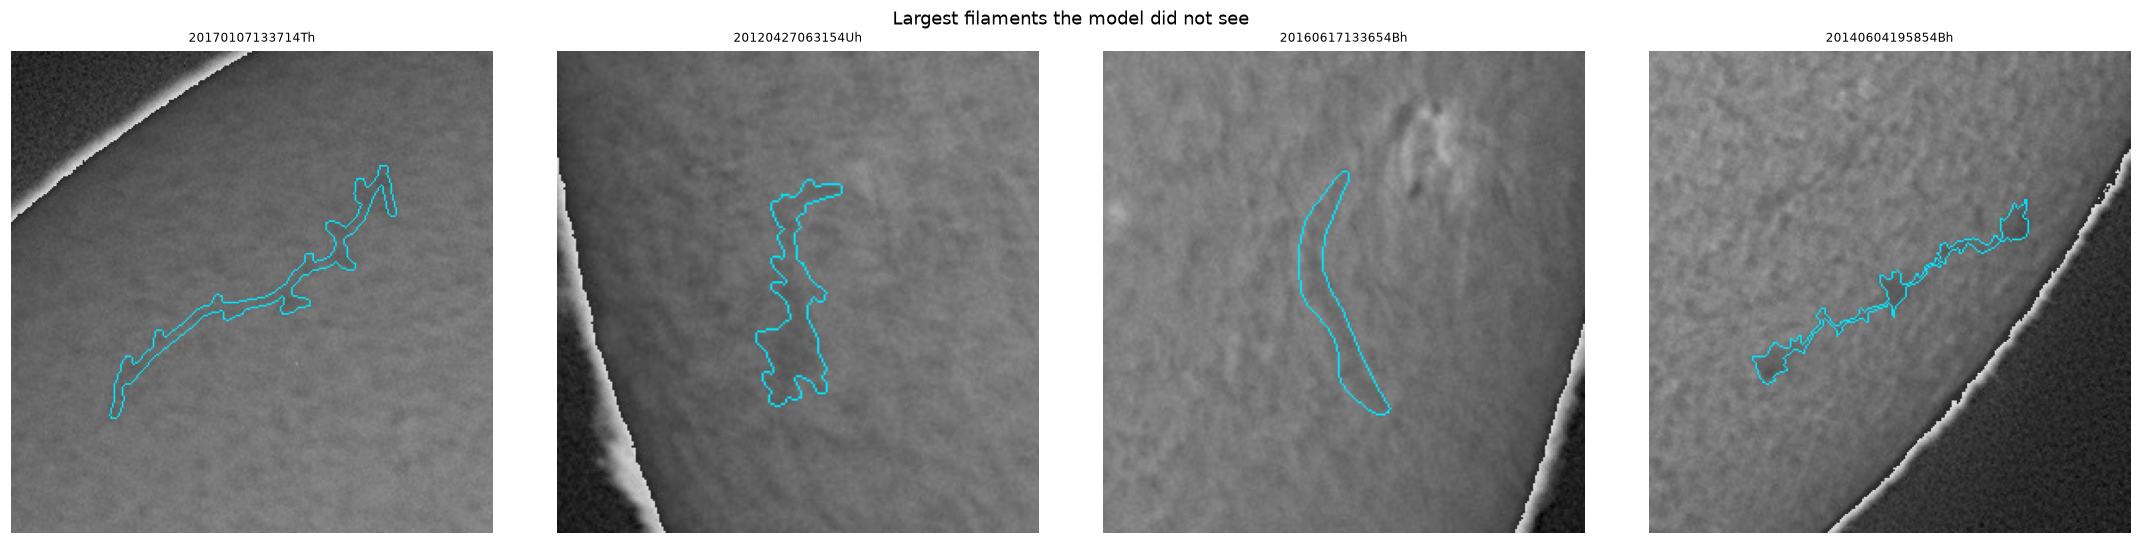

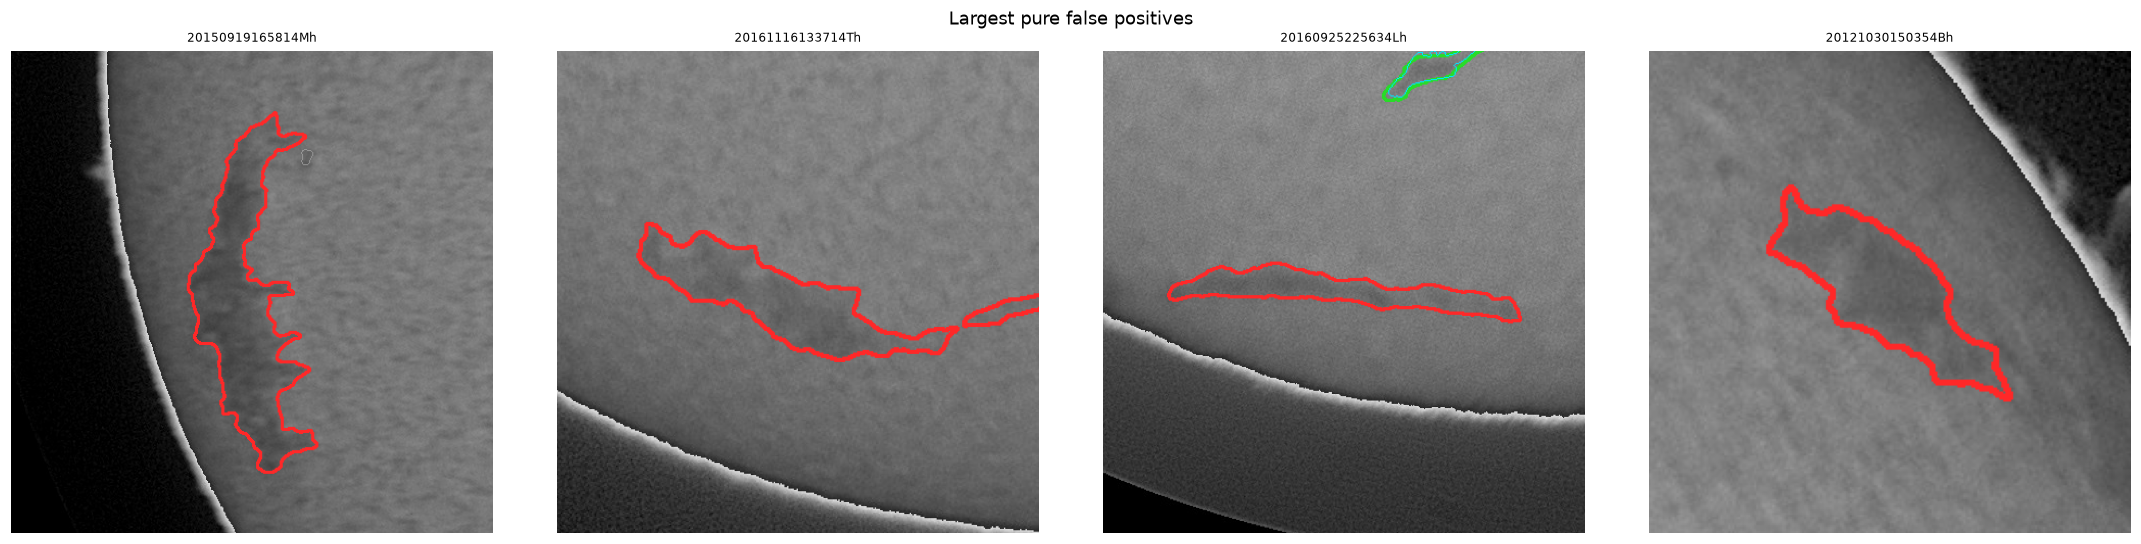

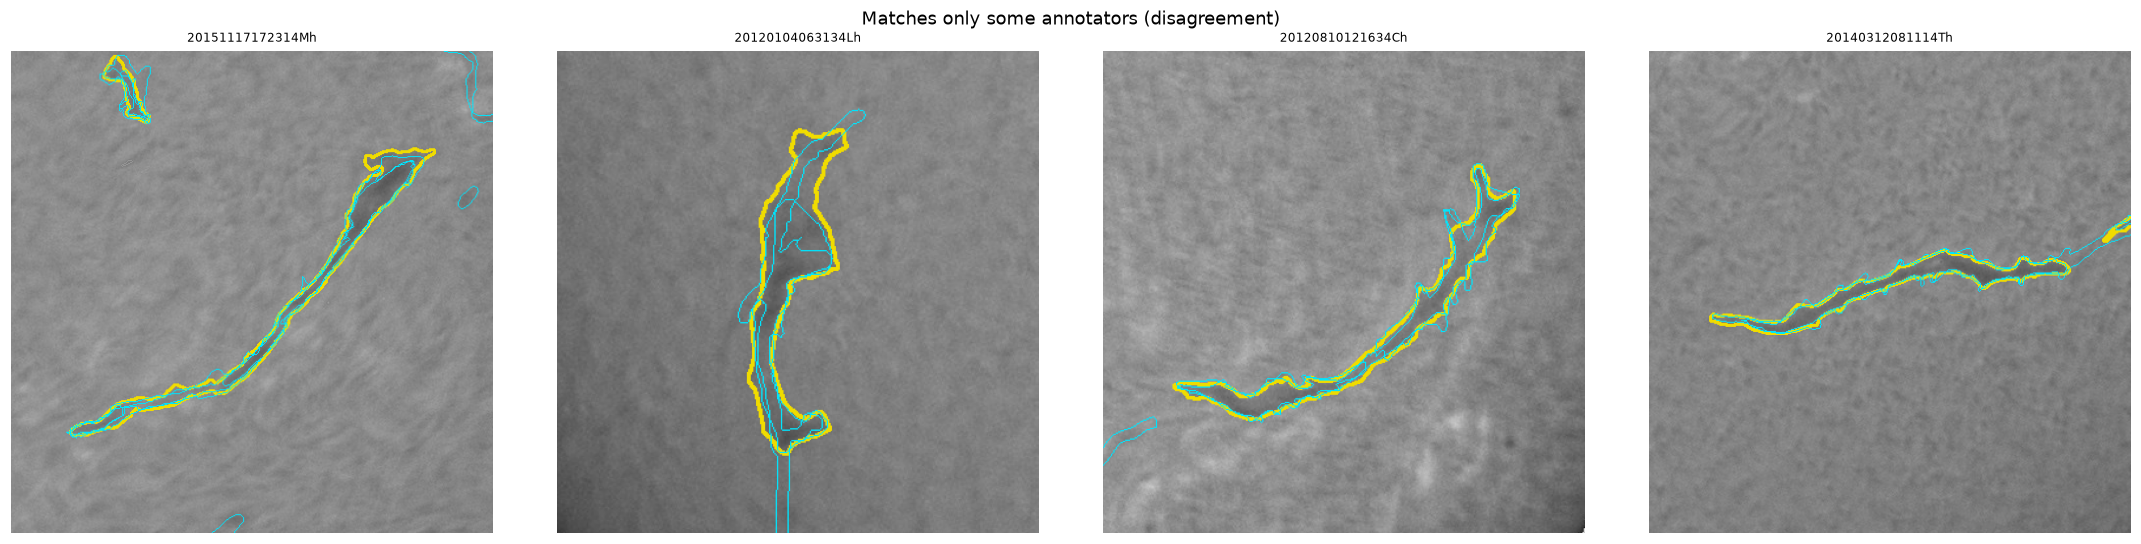

In [10]:
def crops(rows, title, n=4, pad=60):
    fig, axes = plt.subplots(1, n, figsize=(5 * n, 5))
    for ax, (_, r) in zip(axes, rows.head(n).iterrows()):
        h, w = r.y1 - r.y0, r.x1 - r.x0; s = max(h, w) // 2 + pad; cy, cx = (r.y0 + r.y1) // 2, (r.x0 + r.x1) // 2
        overlay(r.stem, crop=(cy - s, cy + s, cx - s, cx + s), ax=ax, title=f"{r.stem}")
    plt.suptitle(title); plt.tight_layout()

crops(gt[gt.outcome == "split"].sort_values("area", ascending=False).drop_duplicates("stem"), "Largest split filaments")
crops(gt[(gt.outcome == "missing") & (gt.prob_max < 0.2)].sort_values("area", ascending=False).drop_duplicates("stem"),
      "Largest filaments the model did not see")
crops(pred[pred.kept & (pred.kind == "pure_fp")].sort_values("area", ascending=False).drop_duplicates("stem"),
      "Largest pure false positives")
crops(pred[pred.kept & (pred.kind == "match_some")].sort_values("area", ascending=False).drop_duplicates("stem"),
      "Matches only some annotators (disagreement)")

## Conclusions

See [notes/error_analysis.md](../notes/error_analysis.md).